# Diet and cancer mortality — estimating hazard ratios directly from NHANES

**A companion to the alcohol/GLOBOCAN reconstruction.** That notebook *imports*
the WCRF Continuous Update Project relative risks (alcohol → cancer *incidence*).
Here we instead **estimate diet–cancer hazard ratios ourselves**, from a fully
public prospective resource, for four exposures at once:

> **alcohol · total sugars · total fat · saturated fat → cancer mortality**

This shows the machinery behind a number like "RR 1.15 per 10 g/day" — a
confounder-adjusted, energy-adjusted Cox dose–response model — on open data that
anyone can download without an application.

### Data (no login, no application)
- **NHANES continuous** (CDC): demographics, day-1 24-hour dietary recall, smoking,
  body measures. Public SAS-transport `.xpt` files, cycles 2003–2014.
- **NHANES Public-Use Linked Mortality File** (NCHS): each participant linked to the
  National Death Index through **31 Dec 2019**, with cause of death. This turns the
  cross-sectional survey into a **retrospective mortality cohort**.

## 0 · What this is, and four honest caveats

We model the **cause-specific hazard of cancer death** (`UCOD_LEADING == 2`,
malignant neoplasms) as a function of usual diet, adjusting for age, sex,
race/ethnicity, education, smoking, BMI and total energy — the same confounder set
the WCRF cohorts used. But a template is not a definitive estimate:

1. **Mortality, not incidence.** WCRF/Rumgay model who *gets* cancer; we model who
   *dies* of it. Mortality blends incidence with survival and treatment.
2. **One 24-hour recall.** A single day of intake is a noisy proxy for usual diet.
   This **regression dilution** biases diet–outcome associations *toward the null* —
   so expect our HRs to be *attenuated* versus WCRF's.
3. **Reverse causation / sick-quitters.** People already ill (incl. undiagnosed
   cancer) often cut alcohol and eat differently, which can *mask or invert* a true
   harmful effect in a mortality cohort.
4. **Survey design.** The primary fit is unweighted; NHANES' weights and
   PSU/stratum design are only approximated in a weighted sensitivity fit. Full
   population inference needs Taylor-linearized survey variance.

Keep these in mind: the *point* of this notebook is the **method and its limits**,
and the instructive contrast between a mortality/recall estimate and WCRF's
incidence estimate.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nhanes_pipeline as N
import nhanes_cox as C

# ---- shared palette (matches the reconstruction notebook) ----
CAT = ["#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#008300","#4a3aa7","#e34948"]
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#e8e8e5", "#ffffff"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "figure.dpi": 110,
})
print("Exposures:", ", ".join(f"{s['label']} ({k})" for k, s in N.EXPOSURES.items()))
print("Cycles   :", ", ".join(N.DEFAULT_CYCLES))

Exposures: Alcohol (alcohol_g), Total sugars (sugar_g), Total fat (totfat_g), Saturated fat (satfat_g)
Cycles   : 2003-2004, 2005-2006, 2007-2008, 2009-2010, 2011-2012, 2013-2014


## 1 · Download and build the cohort

`N.build_cohort()` downloads (and caches to `data/nhanes/`) each cycle's demographics,
dietary, smoking, body-measure and mortality files, merges them on the respondent id
`SEQN`, and applies the analytic filters: **mortality-eligible adults aged ≥20**, a
**reliable** day-1 recall, plausible energy intake (500–5000 kcal), positive
follow-up time and complete covariates.

In [2]:
coh = N.build_cohort()
print(f"analytic sample : {len(coh):,} adults")
print(f"cancer deaths   : {coh.event_cancer.sum():,}")
print(f"all-cause deaths: {coh.event_death.sum():,}")
print(f"median follow-up: {coh.time_years.median():.1f} years")

by_cycle = (coh.groupby("cycle")
              .agg(n=("SEQN","size"),
                   cancer_deaths=("event_cancer","sum"),
                   all_deaths=("event_death","sum")))
by_cycle

analytic sample : 28,884 adults
cancer deaths   : 1,023
all-cause deaths: 4,391
median follow-up: 9.9 years


,n,cancer_deaths,all_deaths
cycle,,,
2003-2004,4243,252,1137
2005-2006,4336,172,810
2007-2008,5215,219,918
2009-2010,5583,186,719
2011-2012,4634,120,473
2013-2014,4873,74,334


## 2 · The exposures and energy adjustment

Each exposure comes from the day-1 recall (grams/day). The challenge the WCRF
meta-analyses also faced: **total energy intake confounds every nutrient** — eat more
of everything and every gram count rises together. We apply the **Willett residual
method**: regress the nutrient on energy, take the residual, and add back the mean.
The result is an intake *uncorrelated with total energy*, isolating diet *composition*
from diet *quantity*. (Alcohol and energy are also both kept as model covariates.)

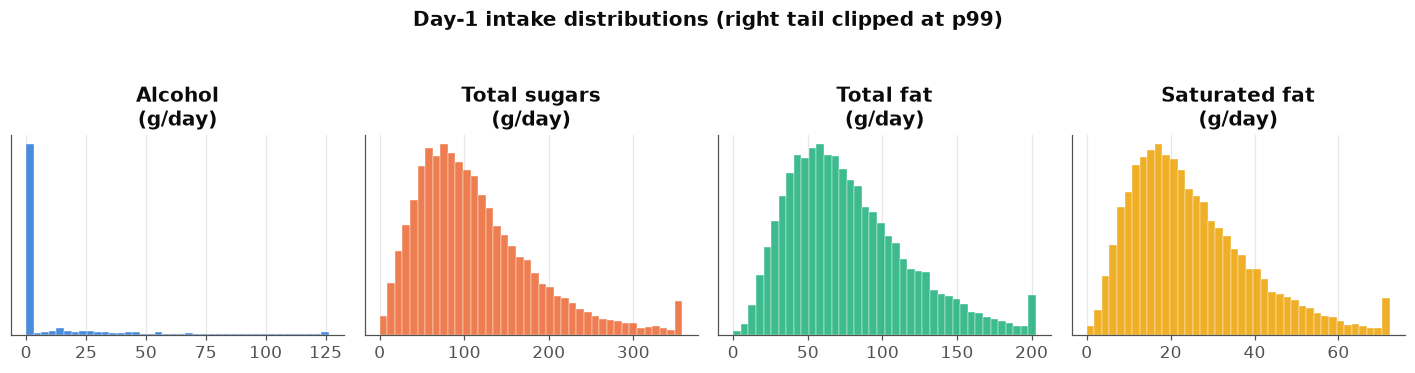

Saturated fat vs total energy:
  raw    corr(energy) = +0.784
  adjusted corr(energy) = -0.000  (removed by design)


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (key, spec), c in zip(axes, N.EXPOSURES.items(), CAT):
    v = coh[key].clip(upper=coh[key].quantile(0.99))
    ax.hist(v, bins=40, color=c, alpha=0.85, edgecolor="white", linewidth=0.3)
    ax.set_title(f"{spec['label']}\n({spec['unit']})")
    ax.set_yticks([])
fig.suptitle("Day-1 intake distributions (right tail clipped at p99)", y=1.05, fontweight="bold")
plt.tight_layout(); plt.show()

# illustrate energy adjustment on saturated fat
adj = N.energy_adjust(coh, "satfat_g")
print("Saturated fat vs total energy:")
print(f"  raw    corr(energy) = {np.corrcoef(coh.satfat_g, coh.energy_kcal)[0,1]:+.3f}")
print(f"  adjusted corr(energy) = {np.corrcoef(adj, coh.energy_kcal)[0,1]:+.3f}  (removed by design)")

## 3 · Cox dose–response models

For each exposure we fit a **cause-specific Cox proportional-hazards model** for
time-to-cancer-death, with the energy-adjusted exposure plus confounders
(age, sex, race/ethnicity, education, smoking, BMI, total energy). We report the HR
**per natural increment** (e.g. per 10 g/day alcohol, to echo WCRF) and **per 1 SD**
of the energy-adjusted exposure, so the four diet factors sit on one comparable scale.

In [4]:
res = C.run_all(coh, weighted=False)
show = res.copy()
for c in ["HR_per_unit","lci_unit","uci_unit","HR_per_sd","lci_sd","uci_sd"]:
    show[c] = show[c].round(3)
show["p"] = show["p"].round(3)
show[["exposure","per_unit","HR_per_unit","lci_unit","uci_unit","HR_per_sd","lci_sd","uci_sd","p","events"]]

,exposure,per_unit,HR_per_unit,lci_unit,uci_unit,HR_per_sd,lci_sd,uci_sd,p,events
0,Alcohol,per 10 g/day,0.996,0.968,1.025,0.990,0.922,1.064,0.788,1023
1,Total sugars,per 50 g/day,1.030,0.968,1.096,1.034,0.963,1.110,0.354,1023
2,Total fat,per 25 g/day,1.037,0.956,1.125,1.032,0.963,1.106,0.377,1023
3,Saturated fat,per 10 g/day,1.092,1.015,1.174,1.084,1.014,1.159,0.018,1023


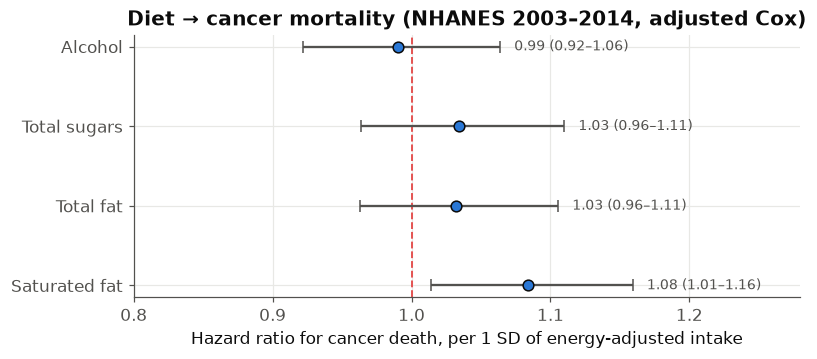

In [5]:
# forest plot: HR per 1 SD of energy-adjusted intake
fig, ax = plt.subplots(figsize=(7.5, 3.4))
y = np.arange(len(res))[::-1]
ax.errorbar(res.HR_per_sd, y,
            xerr=[res.HR_per_sd - res.lci_sd, res.uci_sd - res.HR_per_sd],
            fmt="o", color=INK, ecolor=MUTED, capsize=4, markersize=7,
            markerfacecolor=BLUE, markeredgecolor=INK, zorder=3)
ax.axvline(1.0, color=RED, lw=1.2, ls="--", zorder=1)
ax.set_yticks(y); ax.set_yticklabels(res.exposure)
ax.set_xlabel("Hazard ratio for cancer death, per 1 SD of energy-adjusted intake")
ax.set_title("Diet → cancer mortality (NHANES 2003–2014, adjusted Cox)")
for yi, (_, r) in zip(y, res.iterrows()):
    ax.text(r.uci_sd + 0.01, yi, f"{r.HR_per_sd:.2f} ({r.lci_sd:.2f}–{r.uci_sd:.2f})",
            va="center", fontsize=9, color=MUTED)
ax.set_xlim(0.80, max(1.25, res.uci_sd.max() + 0.12))
plt.tight_layout(); plt.show()

## 4 · Survey-weighted sensitivity

NHANES is a complex multistage sample. A fully correct population estimate uses the
MEC exam weights with the design strata/PSUs. `lifelines` can take the pooled weights
(`WTMEC2YR / n_cycles`) with cluster-robust standard errors — an **approximation**
that shifts estimates toward the US adult population but does *not* fully reproduce
Taylor-linearized survey variance. Compare against the unweighted fit above.

In [6]:
resw = C.run_all(coh, weighted=True)
cmp = res[["exposure","HR_per_sd","lci_sd","uci_sd"]].merge(
        resw[["exposure","HR_per_sd","lci_sd","uci_sd"]],
        on="exposure", suffixes=("_unwt","_wtd"))
cmp.round(3)

,exposure,HR_per_sd_unwt,lci_sd_unwt,uci_sd_unwt,HR_per_sd_wtd,lci_sd_wtd,uci_sd_wtd
0,Alcohol,0.990,0.922,1.064,0.970,0.877,1.072
1,Total sugars,1.034,0.963,1.110,1.046,0.943,1.159
2,Total fat,1.032,0.963,1.106,1.011,0.928,1.103
3,Saturated fat,1.084,1.014,1.159,1.092,0.998,1.196


## 5 · Reading the results against WCRF

A few patterns to expect, and why they are *scientifically* interesting rather than
contradictory:

- **Alcohol looks weak/null here**, despite WCRF's clear positive incidence RRs. This
  is the caveats biting, in textbook fashion: a single 24-hour recall misclassifies
  usual alcohol intake severely (many true drinkers report zero on the recall day →
  regression dilution → attenuation), the outcome is *mortality* not incidence, and
  sick-quitter reverse causation in a mortality cohort pulls the estimate down. It is
  a clean demonstration of *why* WCRF needed many large cohorts with repeated,
  validated dietary assessment to resolve the signal.
- **Saturated fat / composition signals** may reach nominal significance — but with
  diet, residual confounding (overall dietary pattern, SES) and the energy-partition
  problem mean these are *hypothesis-generating*, not causal.
- **Confidence intervals here are random error only.** As in the sister notebook, they
  do not capture measurement error or unmeasured confounding (stress, pollution,
  radiation, ultra-processed foods are all absent), so the *true* uncertainty is wider.

**Takeaway.** The same Cox/energy-adjustment machinery that underlies WCRF's per-10g
numbers is reproducible on open data in a few hundred lines — but reproducing WCRF's
*conclusions* needs incidence outcomes and repeated, validated diet measurement that
NHANES' single recall cannot provide.

## 6 · Extending the template

The pipeline is deliberately factored so the hard parts are swappable:

- **Better exposure.** Use the 2-day average (`DR1`+`DR2`) or the ALQ alcohol
  questionnaire for usual intake; add the USDA FPED merge for *added* sugars.
- **Incidence, not mortality.** Point `N.build_cohort` at a cohort with incident-cancer
  follow-up. The natural upgrade is **UK Biobank** (cancer-registry linked, ~500k,
  plus pollution/SES/genetics) — swap the loader, keep `nhanes_cox` almost verbatim.
- **Causal identification.** Add a Mendelian-randomisation arm (ALDH2/ADH variants)
  to probe alcohol causality free of lifestyle confounding.

Modules: `src/nhanes_pipeline.py` (download + cohort + energy adjustment),
`src/nhanes_cox.py` (Cox estimation). Rebuild this notebook with
`.venv/bin/python src/build_nhanes_notebook.py`.

---
*Sources: NHANES continuous (CDC/NCHS) · NHANES Public-Use Linked Mortality Files
(NCHS, linkage through 2019) · method after Willett, Nutritional Epidemiology.*